# Comparação de modelos de classificação de sentimento

Treina e compara três abordagens nos dados de **r/brdev** e **r/datasciencebr**. Os rótulos vêm da OpenAI Decisions API.

| # | Abordagem | O que é treinado |
|---|---|---|
| 1 | **TF-IDF + Naive Bayes** | Modelo clássico, baseline |
| 2 | **pysentimiento/bertweet-pt-sentiment** | Só as **camadas finais**: as últimas camadas do encoder + a cabeça de classificação |
| 3 | **neuralmind/bert-large-portuguese-cased** (BERTimbau) | **Todas as camadas** (fine-tuning completo) |

**Dados:** as bases já preparadas por `scripts/preparar_base_treino.py`.
- `treino_conf_0.7.csv`: só rótulos com confiança > 0,7. Daqui sai também a validação, com 10%.
- `teste.csv`: 15% de todos os dados, **sem filtro de confiança**, que nunca aparecem no treino.

Os três modelos usam exatamente os mesmos dados.

> ⚠️ **As métricas medem a concordância com os rótulos da API, não com a verdade.** Para avaliar a qualidade real, use o conjunto de referência anotado por humanos (seção 6 do README).

### Antes de rodar
1. **No Google Drive**, crie a pasta `MyDrive/analise_sentimento/dados_treino/` e coloque nela os arquivos `treino_conf_0.7.csv` e `teste.csv`.
2. **No Colab**: *Ambiente de execução → Alterar o tipo de ambiente de execução → **GPU (T4)***.
3. Rode as células em ordem. O notebook pede autorização para acessar o Drive.

### O que fica salvo no Drive (`MyDrive/analise_sentimento/`)
```
modelos/<EXPERIMENTO>/
├── 1_tfidf_naive_bayes/modelo.joblib          # pipeline TF-IDF + NB
├── 2b_bertweet_pt_camadas_finais/             # save_pretrained (modelo + tokenizer)
└── 3_bertimbau_large_completo/                # save_pretrained (modelo + tokenizer)
resultados/<EXPERIMENTO>/
├── metricas_comparacao.csv
├── config_experimento.json
├── historico_treino.json                      # perda e F1 de validação por época
└── predicoes_<modelo>.csv                     # predições no teste, para análise de erros
```
Se o Colab desconectar, rode de novo: **os modelos que já estão no Drive são carregados e avaliados, sem treinar outra vez** (`PULAR_SE_JA_TREINADO = True`).

In [1]:
!pip install -q transformers accelerate scikit-learn emoji joblib

## 1. Configuração

In [ ]:
import os, random, time, json
import numpy as np
import pandas as pd
import torch

# ------------------------- Pastas (Google Drive) -------------------------
PASTA_PROJETO = "/content/drive/MyDrive/analise_sentimento"   # ajuste se usar outro caminho no Drive
ARQ_TREINO = "dados_treino/treino_conf_0.7.csv"                # relativo a PASTA_PROJETO
ARQ_TESTE = "dados_treino/teste.csv"
EXPERIMENTO = "conf_0.7"   # nome da rodada; separa modelos/resultados de experimentos diferentes
PULAR_SE_JA_TREINADO = True  # True = se o modelo já está salvo no Drive, carrega em vez de treinar

# ------------------------- Divisão / avaliação -------------------------
FRAC_VALIDACAO = 0.10      # validação tirada do treino (para escolher a melhor época)
CONF_TESTE_ALTA = 0.7      # métricas extras no subconjunto do teste com confiança >= este valor
SEED = 42

# ------------------------- Modelo 2: BERTweet-PT -------------------------
MODELO_2 = "pysentimiento/bertweet-pt-sentiment"
N_CAMADAS_TREINAVEIS_2 = 2   # últimas N camadas do encoder descongeladas (0 = só a cabeça)
MAX_LEN_2 = 128              # limite do BERTweet
EPOCAS_2, LR_2, BATCH_2 = 4, 5e-5, 32

# ------------------------- Modelo 3: BERTimbau -------------------------
MODELO_3 = "neuralmind/bert-large-portuguese-cased"   # ou "neuralmind/bert-base-portuguese-cased"
INICIALIZAR_DO_ZERO_3 = False  # True = pesos ALEATÓRIOS. Re-treina modelo do zero.
MAX_LEN_3 = 256
EPOCAS_3, LR_3, BATCH_3 = 3, 1e-5, 16
ACUMULACAO_3 = 1             # se faltar memória: BATCH_3 = 8 e ACUMULACAO_3 = 2

# ------------------------- Execução -------------------------
MODO_RAPIDO = False   # True = ~1500 exemplos e 1 época, para testar o notebook (salva em EXPERIMENTO + "_rapido")

def fixar_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
fixar_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "SEM GPU - os modelos BERT serão MUITO lentos")

Dispositivo: cuda | Tesla T4


## 2. Google Drive e dados

In [3]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    PASTA_PROJETO = "."   # fora do Colab: usa a pasta atual (raiz do projeto)
    print("Fora do Colab: usando a pasta atual como PASTA_PROJETO")

if MODO_RAPIDO:
    EXPERIMENTO += "_rapido"
PASTA_MODELOS = os.path.join(PASTA_PROJETO, "modelos", EXPERIMENTO)
PASTA_RESULTADOS = os.path.join(PASTA_PROJETO, "resultados", EXPERIMENTO)
os.makedirs(PASTA_MODELOS, exist_ok=True)
os.makedirs(PASTA_RESULTADOS, exist_ok=True)

for arq in (ARQ_TREINO, ARQ_TESTE):
    caminho = os.path.join(PASTA_PROJETO, arq)
    assert os.path.exists(caminho), f"Arquivo não encontrado: {caminho}\nCopie a pasta dados_treino/ para {PASTA_PROJETO}/ no Drive."

ROTULOS = ["negativo", "neutro", "positivo"]
LABEL2ID = {r: i for i, r in enumerate(ROTULOS)}

def carregar(arq):
    d = pd.read_csv(os.path.join(PASTA_PROJETO, arq), dtype={"id": str})
    d = d.dropna(subset=["texto", "rotulo"]).drop_duplicates("id").reset_index(drop=True)
    d["y"] = d["rotulo"].map(LABEL2ID)
    assert d["y"].notna().all(), f"{arq}: rótulos fora de {ROTULOS}"
    return d

df_treino_total = carregar(ARQ_TREINO)
df_teste = carregar(ARQ_TESTE)
assert not set(df_treino_total["id"]) & set(df_teste["id"]), "Vazamento: ids do teste aparecem no treino!"
print("Modelos ->", PASTA_MODELOS)
print("Resultados ->", PASTA_RESULTADOS)

Mounted at /content/drive
Modelos -> /content/drive/MyDrive/analise_sentimento/modelos/conf_0.7
Resultados -> /content/drive/MyDrive/analise_sentimento/resultados/conf_0.7


### Divisão treino / validação

In [4]:
from sklearn.model_selection import train_test_split

df_treino, df_val = train_test_split(df_treino_total, test_size=FRAC_VALIDACAO,
                                     stratify=df_treino_total["rotulo"], random_state=SEED)

if MODO_RAPIDO:
    df_treino = df_treino.sample(min(1500, len(df_treino)), random_state=SEED)
    df_val = df_val.sample(min(300, len(df_val)), random_state=SEED)
    df_teste = df_teste.sample(min(500, len(df_teste)), random_state=SEED)
    EPOCAS_2 = EPOCAS_3 = 1

df_treino, df_val, df_teste = [d.reset_index(drop=True) for d in (df_treino, df_val, df_teste)]
mask_teste_conf = (df_teste["confidence"] >= CONF_TESTE_ALTA).values

resumo = pd.DataFrame({
    "treino": df_treino["rotulo"].value_counts(),
    "validacao": df_val["rotulo"].value_counts(),
    "teste": df_teste["rotulo"].value_counts(),
}).loc[ROTULOS]
resumo.loc["TOTAL"] = resumo.sum()
print(f"Teste com confiança >= {CONF_TESTE_ALTA}: {mask_teste_conf.sum()} de {len(df_teste)}")
resumo

Teste com confiança >= 0.7: 1633 de 3001


,treino,validacao,teste
rotulo,,,
negativo,3202,356,1060
neutro,2932,326,1137
positivo,2012,224,804
TOTAL,8146,906,3001


## 3. Funções de avaliação e persistência

In [5]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

RESULTADOS, HISTORICO = {}, {}
_arq_hist = os.path.join(PASTA_RESULTADOS, "historico_treino.json")
if os.path.exists(_arq_hist):   # preserva o histórico de modelos treinados em execuções anteriores
    HISTORICO.update(json.load(open(_arq_hist)))

def avaliar(nome, y_pred, tempo_treino_s=None):
    y_true = df_teste["y"].values
    y_pred = np.asarray(y_pred)
    m = {
        "acuracia": accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
        "f1_ponderado": f1_score(y_true, y_pred, average="weighted"),
        **{f"f1_{r}": float(v) for r, v in zip(ROTULOS, f1_score(y_true, y_pred, average=None, labels=[0, 1, 2]))},
        f"f1_macro_teste_conf>={CONF_TESTE_ALTA}": f1_score(y_true[mask_teste_conf], y_pred[mask_teste_conf], average="macro"),
        "tempo_treino_min": None if tempo_treino_s is None else round(tempo_treino_s / 60, 1),
    }
    if "subreddit" in df_teste:
        for s in sorted(df_teste["subreddit"].dropna().unique()):
            k = (df_teste["subreddit"] == s).values
            m[f"f1_macro_{s}"] = f1_score(y_true[k], y_pred[k], average="macro")
    RESULTADOS[nome] = m

    print(f"===== {nome} =====")
    print(classification_report(y_true, y_pred, target_names=ROTULOS, digits=3))
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    fig, ax = plt.subplots(figsize=(4, 3.5))
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(3), ROTULOS); ax.set_yticks(range(3), ROTULOS)
    ax.set_xlabel("predito"); ax.set_ylabel("rótulo (API)"); ax.set_title(nome, fontsize=10)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.tight_layout()
    fig.savefig(os.path.join(PASTA_RESULTADOS, f"matriz_confusao_{nome}.png"), dpi=120)
    plt.show()

    pd.DataFrame({"id": df_teste["id"], "texto": df_teste["texto"], "rotulo_api": df_teste["rotulo"],
                  "confidence_api": df_teste["confidence"], "predito": [ROTULOS[i] for i in y_pred]}
                 ).to_csv(os.path.join(PASTA_RESULTADOS, f"predicoes_{nome}.csv"), index=False)
    salvar_resultados()
    return m

def salvar_resultados():
    # salvo a cada modelo avaliado: se o Colab cair no meio, o que já rodou não se perde
    pd.DataFrame(RESULTADOS).T.to_csv(os.path.join(PASTA_RESULTADOS, "metricas_comparacao.csv"))
    with open(os.path.join(PASTA_RESULTADOS, "historico_treino.json"), "w") as f:
        json.dump(HISTORICO, f, indent=2)

def ja_treinado(pasta):
    return PULAR_SE_JA_TREINADO and os.path.exists(os.path.join(pasta, "TREINO_CONCLUIDO.json"))

def marcar_concluido(pasta, info):
    with open(os.path.join(pasta, "TREINO_CONCLUIDO.json"), "w") as f:
        json.dump({"experimento": EXPERIMENTO, "n_treino": len(df_treino), "n_validacao": len(df_val),
                   "data": time.strftime("%Y-%m-%d %H:%M:%S"), **info}, f, indent=2, ensure_ascii=False)

## 4. Abordagem 1: TF-IDF + Naive Bayes

- **TF-IDF** com unigramas e bigramas, `sublinear_tf`, removendo termos muito raros (`min_df=2`) e muito frequentes (`max_df=0.9`). Os acentos e as stopwords são mantidos de propósito: palavras como "não" carregam sentimento.
- **Multinomial Naive Bayes**: o `alpha` (suavização) é escolhido na validação.
- O pipeline completo (vetorizador + modelo) é salvo com `joblib`.

alpha=0.01  F1-macro validação=0.7199
alpha=0.05  F1-macro validação=0.7391
alpha=0.1   F1-macro validação=0.7229
alpha=0.3   F1-macro validação=0.6674
alpha=0.5   F1-macro validação=0.6387
alpha=1.0   F1-macro validação=0.5815
Melhor alpha: 0.05 | salvo em /content/drive/MyDrive/analise_sentimento/modelos/conf_0.7/1_tfidf_naive_bayes/modelo.joblib
===== 1_tfidf_naive_bayes =====
              precision    recall  f1-score   support

    negativo      0.555     0.792     0.652      1060
      neutro      0.709     0.558     0.625      1137
    positivo      0.597     0.440     0.507       804

    accuracy                          0.609      3001
   macro avg      0.620     0.597     0.595      3001
weighted avg      0.625     0.609     0.603      3001



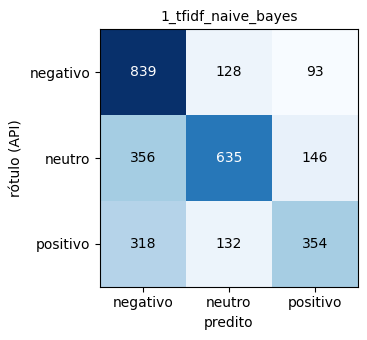

{'acuracia': 0.6091302899033656,
 'f1_macro': 0.5946524338284164,
 'f1_ponderado': 0.6029253136535939,
 'f1_negativo': 0.6521570151574038,
 'f1_neutro': 0.625,
 'f1_positivo': 0.5068002863278454,
 'f1_macro_teste_conf>=0.7': 0.714055405100881,
 'tempo_treino_min': 0.5,
 'f1_macro_brdev': 0.546968558905828,
 'f1_macro_datasciencebr': 0.6171169082984106}

In [6]:
import joblib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline

nome1 = "1_tfidf_naive_bayes"
pasta1 = os.path.join(PASTA_MODELOS, nome1); os.makedirs(pasta1, exist_ok=True)
arq1 = os.path.join(pasta1, "modelo.joblib")

if ja_treinado(pasta1):
    print("Carregando modelo salvo:", arq1)
    pipe1 = joblib.load(arq1); tempo1 = None
else:
    t0 = time.time()
    melhor = None
    for alpha in [0.01, 0.05, 0.1, 0.3, 0.5, 1.0]:
        pipe = make_pipeline(TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True),
                             MultinomialNB(alpha=alpha)).fit(df_treino["texto"], df_treino["y"])
        f1 = f1_score(df_val["y"], pipe.predict(df_val["texto"]), average="macro")
        print(f"alpha={alpha:<5} F1-macro validação={f1:.4f}")
        if melhor is None or f1 > melhor[0]:
            melhor = (f1, alpha, pipe)
    pipe1, tempo1 = melhor[2], time.time() - t0
    HISTORICO[nome1] = {"melhor_alpha": melhor[1], "f1_validacao": melhor[0]}
    joblib.dump(pipe1, arq1)
    marcar_concluido(pasta1, {"alpha": melhor[1], "f1_validacao": melhor[0], "rotulos": ROTULOS})
    print(f"Melhor alpha: {melhor[1]} | salvo em {arq1}")

avaliar(nome1, pipe1.predict(df_teste["texto"]), tempo1)

## Utilitários para os modelos Transformer

Laço de treino em PyTorch puro, inclui:
- AdamW com aquecimento (*warmup*) linear de 10%;
- precisão mista (fp16) na GPU;
- avaliação a cada época na validação, mantendo os pesos da época com **maior F1-macro**.

Ao final, o modelo e o tokenizer são salvos no Drive com `save_pretrained`. Depois, dá para carregar com `AutoModelForSequenceClassification.from_pretrained(pasta)`.

In [7]:
from torch.utils.data import DataLoader
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, AutoConfig,
                          DataCollatorWithPadding, get_linear_schedule_with_warmup)

class TextosDataset(torch.utils.data.Dataset):
    def __init__(self, textos, ys, tok, max_len):
        self.enc = tok(list(textos), truncation=True, max_length=max_len)
        self.ys = list(ys)
    def __len__(self): return len(self.ys)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = int(self.ys[i])
        return item

def make_loader(d, tok, max_len, batch, shuffle):
    ds = TextosDataset(d["texto"], d["y"], tok, max_len)
    return DataLoader(ds, batch_size=batch, shuffle=shuffle, collate_fn=DataCollatorWithPadding(tok))

@torch.no_grad()
def prever(model, loader, mapa_saida=None):
    model.eval(); preds = []
    for b in loader:
        b = {k: v.to(DEVICE) for k, v in b.items() if k != "labels"}
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            logits = model(**b).logits
        p = logits.argmax(-1).cpu().numpy()
        preds.extend(mapa_saida[p] if mapa_saida is not None else p)
    return np.array(preds)

def treinar(nome, model, tok, max_len, epocas, lr, batch, acumulacao=1, mapa_saida=None):
    tl = make_loader(df_treino, tok, max_len, batch, shuffle=True)
    vl = make_loader(df_val, tok, max_len, batch * 2, shuffle=False)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.01)
    passos = epocas * len(tl) // acumulacao
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * passos), passos)
    scaler = torch.amp.GradScaler(enabled=DEVICE.type == "cuda")
    # se a cabeça do modelo tiver outra ordem de classes, os rótulos do treino são convertidos para ela
    y_para_modelo = None if mapa_saida is None else {int(v): k for k, v in enumerate(mapa_saida)}

    hist, melhor_f1, melhor_estado = [], -1, None
    for ep in range(1, epocas + 1):
        model.train(); t0 = time.time(); perda_total = 0
        for i, b in enumerate(tl):
            if y_para_modelo is not None:
                b["labels"] = torch.tensor([y_para_modelo[int(y)] for y in b["labels"]])
            b = {k: v.to(DEVICE) for k, v in b.items()}
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
                perda = model(**b).loss / acumulacao
            scaler.scale(perda).backward()
            perda_total += perda.item() * acumulacao
            if (i + 1) % acumulacao == 0 or i + 1 == len(tl):
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, 1.0)
                scaler.step(opt); scaler.update(); opt.zero_grad(); sched.step()
        f1_val = f1_score(df_val["y"], prever(model, vl, mapa_saida), average="macro")
        hist.append({"epoca": ep, "perda_treino": perda_total / len(tl), "f1_macro_validacao": f1_val, "segundos": round(time.time() - t0)})
        print(f"época {ep}/{epocas} | perda treino {perda_total/len(tl):.4f} | F1-macro validação {f1_val:.4f} | {time.time()-t0:.0f}s")
        if f1_val > melhor_f1:
            melhor_f1 = f1_val
            melhor_estado = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(melhor_estado)
    HISTORICO[nome] = {"epocas": hist, "melhor_f1_validacao": melhor_f1}
    print(f"Melhor F1-macro na validação: {melhor_f1:.4f}")
    return model

def salvar_modelo(model, tok, pasta, info):
    model.save_pretrained(pasta)
    tok.save_pretrained(pasta)
    marcar_concluido(pasta, info)
    print("Modelo salvo em", pasta)

def contar_parametros(model):
    total = sum(p.numel() for p in model.parameters())
    trein = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Parâmetros treináveis: {trein/1e6:.1f}M de {total/1e6:.1f}M ({trein/total:.1%})")

def liberar_memoria():
    import gc; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

## 5. Abordagem 2: BERTweet-PT, treinando só as camadas finais

O `pysentimiento/bertweet-pt-sentiment` **já foi treinado para sentimento** (NEG/NEU/POS) em tweets em português. Por isso:
1. **Primeiro ele é avaliado sem nenhum treino** (*zero-shot*), para medir quanto o domínio Twitter se transfere para o Reddit.
2. Depois, **congela o modelo inteiro e descongela só as últimas `N_CAMADAS_TREINAVEIS_2` camadas do encoder e a cabeça de classificação**. A cabeça original é mantida, com as classes mapeadas para os nossos rótulos.

Textos com mais de 128 tokens são truncados, porque esse é o limite do modelo.

O modelo salvo tem os rótulos em português (`negativo`/`neutro`/`positivo`) no `config.json`.

config.json:   0%|          | 0.00/952 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/562 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/799k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/22.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  540MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Classes do modelo: {0: 'NEG', 1: 'NEU', 2: 'POS'} -> nossos ids: [0 1 2]
===== 2a_bertweet_pt_zero_shot =====
              precision    recall  f1-score   support

    negativo      0.835     0.419     0.558      1060
      neutro      0.488     0.913     0.636      1137
    positivo      0.710     0.301     0.423       804

    accuracy                          0.574      3001
   macro avg      0.677     0.544     0.539      3001
weighted avg      0.670     0.574     0.551      3001



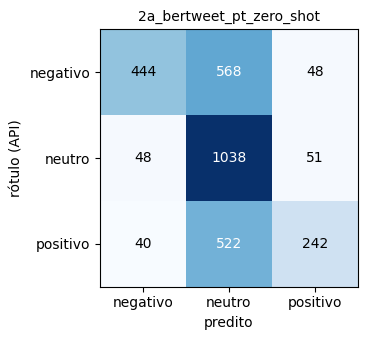

{'acuracia': 0.5744751749416861,
 'f1_macro': 0.5387769925996814,
 'f1_ponderado': 0.5511686107835365,
 'f1_negativo': 0.5577889447236181,
 'f1_neutro': 0.6358346094946401,
 'f1_positivo': 0.422707423580786,
 'f1_macro_teste_conf>=0.7': 0.6390967583796818,
 'tempo_treino_min': None,
 'f1_macro_brdev': 0.5310985714585388,
 'f1_macro_datasciencebr': 0.5342315535559841}

In [8]:
nome2 = "2b_bertweet_pt_camadas_finais"
pasta2 = os.path.join(PASTA_MODELOS, nome2)
pref = {"neg": "negativo", "neu": "neutro", "pos": "positivo"}

def mapa_saida(model):
    # ordem de classes da cabeça do modelo -> nossos ids
    id2label = model.config.id2label
    chaves = [str(id2label[i]).lower()[:3] for i in range(len(id2label))]
    assert all(c in pref for c in chaves), f"Classes inesperadas: {id2label}"
    return np.array([LABEL2ID[pref[c]] for c in chaves])

tok2 = AutoTokenizer.from_pretrained(MODELO_2)
teste_loader2 = make_loader(df_teste, tok2, MAX_LEN_2, 64, shuffle=False)

# 2a) zero-shot (modelo original, sem treino)
model2 = AutoModelForSequenceClassification.from_pretrained(MODELO_2).to(DEVICE)
MAPA_SAIDA_2 = mapa_saida(model2)
print("Classes do modelo:", model2.config.id2label, "-> nossos ids:", MAPA_SAIDA_2)
avaliar("2a_bertweet_pt_zero_shot", prever(model2, teste_loader2, MAPA_SAIDA_2))

Parâmetros treináveis: 14.8M de 134.9M (10.9%)
época 1/4 | perda treino 0.4983 | F1-macro validação 0.8507 | 23s
época 2/4 | perda treino 0.3575 | F1-macro validação 0.8615 | 21s
época 3/4 | perda treino 0.3054 | F1-macro validação 0.8668 | 21s
época 4/4 | perda treino 0.2752 | F1-macro validação 0.8631 | 23s
Melhor F1-macro na validação: 0.8668


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modelo salvo em /content/drive/MyDrive/analise_sentimento/modelos/conf_0.7/2b_bertweet_pt_camadas_finais
===== 2b_bertweet_pt_camadas_finais =====
              precision    recall  f1-score   support

    negativo      0.688     0.817     0.747      1060
      neutro      0.799     0.706     0.750      1137
    positivo      0.715     0.655     0.684       804

    accuracy                          0.732      3001
   macro avg      0.734     0.726     0.727      3001
weighted avg      0.737     0.732     0.731      3001



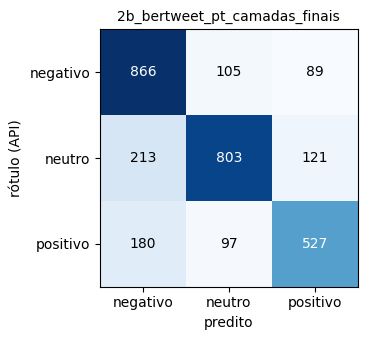

In [9]:
# 2b) congela tudo, libera as últimas N camadas do encoder + cabeça
if ja_treinado(pasta2):
    print("Carregando modelo salvo:", pasta2)
    del model2; liberar_memoria()
    model2 = AutoModelForSequenceClassification.from_pretrained(pasta2).to(DEVICE)
    tempo2 = None
else:
    for p in model2.parameters():
        p.requires_grad = False
    camadas = model2.base_model.encoder.layer
    for camada in (camadas[len(camadas) - N_CAMADAS_TREINAVEIS_2:] if N_CAMADAS_TREINAVEIS_2 > 0 else []):
        for p in camada.parameters():
            p.requires_grad = True
    for nome_p, p in model2.named_parameters():
        if not nome_p.startswith(model2.base_model_prefix + "."):   # cabeça de classificação
            p.requires_grad = True
    contar_parametros(model2)

    fixar_seed(); t0 = time.time()
    model2 = treinar(nome2, model2, tok2, MAX_LEN_2, EPOCAS_2, LR_2, BATCH_2, mapa_saida=MAPA_SAIDA_2)
    tempo2 = time.time() - t0
    # grava os rótulos em português no config, mantendo a ordem da cabeça original
    model2.config.id2label = {i: ROTULOS[MAPA_SAIDA_2[i]] for i in range(len(MAPA_SAIDA_2))}
    model2.config.label2id = {v: k for k, v in model2.config.id2label.items()}
    salvar_modelo(model2, tok2, pasta2, {"modelo_base": MODELO_2, "n_camadas_treinaveis": N_CAMADAS_TREINAVEIS_2,
                                         "max_len": MAX_LEN_2, "epocas": EPOCAS_2, "lr": LR_2, "batch": BATCH_2,
                                         "historico": HISTORICO.get(nome2)})

avaliar(nome2, prever(model2, teste_loader2, mapa_saida(model2)), tempo2)
del model2; liberar_memoria()

## 6. Abordagem 3: BERTimbau, todas as camadas

O BERTimbau é um modelo de linguagem genérico em português, sem treino de sentimento. A cabeça de classificação (3 classes) é **nova, com pesos aleatórios**, e **todas as camadas** são ajustadas.

- Taxa de aprendizado baixa (`1e-5`), porque o BERT large é instável com taxas altas.
- Se faltar memória na GPU, use `BATCH_3 = 8` e `ACUMULACAO_3 = 2`.
- O BERT large salvo ocupa **cerca de 1,3 GB** no Drive.

config.json:   0%|          | 0.00/648 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/155 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.34GB            

... (4 outputs left out)

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-large-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from t

Parâmetros treináveis: 334.4M de 334.4M (100.0%)
época 1/3 | perda treino 0.5042 | F1-macro validação 0.8948 | 354s
época 2/3 | perda treino 0.1717 | F1-macro validação 0.9119 | 356s
época 3/3 | perda treino 0.0768 | F1-macro validação 0.9069 | 350s
Melhor F1-macro na validação: 0.9119


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modelo salvo em /content/drive/MyDrive/analise_sentimento/modelos/conf_0.7/3_bertimbau_large_completo
===== 3_bertimbau_large_completo =====
              precision    recall  f1-score   support

    negativo      0.729     0.850     0.785      1060
      neutro      0.833     0.712     0.768      1137
    positivo      0.722     0.713     0.717       804

    accuracy                          0.761      3001
   macro avg      0.761     0.758     0.757      3001
weighted avg      0.766     0.761     0.760      3001



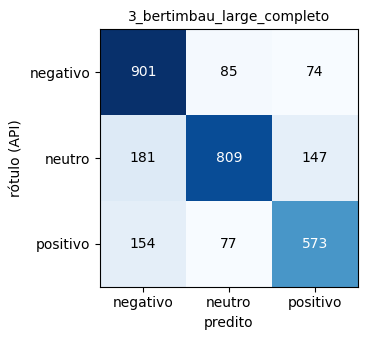

In [10]:
nome3 = "3_bertimbau_" + ("large" if "large" in MODELO_3 else "base") + ("_do_zero" if INICIALIZAR_DO_ZERO_3 else "_completo")
pasta3 = os.path.join(PASTA_MODELOS, nome3)

if ja_treinado(pasta3):
    print("Carregando modelo salvo:", pasta3)
    tok3 = AutoTokenizer.from_pretrained(pasta3)
    model3 = AutoModelForSequenceClassification.from_pretrained(pasta3).to(DEVICE)
    tempo3 = None
else:
    tok3 = AutoTokenizer.from_pretrained(MODELO_3)
    kw = dict(num_labels=3, id2label=dict(enumerate(ROTULOS)), label2id=LABEL2ID)
    if INICIALIZAR_DO_ZERO_3:
        model3 = AutoModelForSequenceClassification.from_config(AutoConfig.from_pretrained(MODELO_3, **kw))
        print("⚠️ Pesos ALEATÓRIOS (treino do zero)")
    else:
        model3 = AutoModelForSequenceClassification.from_pretrained(MODELO_3, **kw)
    model3.to(DEVICE)
    contar_parametros(model3)

    fixar_seed(); t0 = time.time()
    model3 = treinar(nome3, model3, tok3, MAX_LEN_3, EPOCAS_3, LR_3, BATCH_3, acumulacao=ACUMULACAO_3)
    tempo3 = time.time() - t0
    salvar_modelo(model3, tok3, pasta3, {"modelo_base": MODELO_3, "do_zero": INICIALIZAR_DO_ZERO_3, "max_len": MAX_LEN_3,
                                         "epocas": EPOCAS_3, "lr": LR_3, "batch": BATCH_3, "acumulacao": ACUMULACAO_3,
                                         "historico": HISTORICO.get(nome3)})

avaliar(nome3, prever(model3, make_loader(df_teste, tok3, MAX_LEN_3, 64, shuffle=False)), tempo3)
del model3; liberar_memoria()

## 7. Comparação final

**Métrica principal: F1-macro.** Ela dá o mesmo peso às 3 classes, então um modelo que acerta só a classe majoritária não aparece bem.

As métricas medem a concordância com os rótulos da Decisions API em `teste.csv`, que não passou por filtro de confiança.

`tempo_treino_min` aparece vazio para o zero-shot, que não tem treino, e para os modelos carregados do Drive.

In [11]:
tabela = pd.DataFrame(RESULTADOS).T
cols = ["f1_macro", "acuracia", "f1_ponderado", "f1_negativo", "f1_neutro", "f1_positivo", f"f1_macro_teste_conf>={CONF_TESTE_ALTA}"]
cols += [c for c in tabela.columns if c.startswith("f1_macro_") and c not in cols] + ["tempo_treino_min"]
tabela = tabela[cols].sort_values("f1_macro", ascending=False)
tabela.to_csv(os.path.join(PASTA_RESULTADOS, "metricas_comparacao.csv"))

config = {k: globals()[k] for k in ["EXPERIMENTO", "ARQ_TREINO", "ARQ_TESTE", "FRAC_VALIDACAO", "CONF_TESTE_ALTA", "SEED",
          "MODELO_2", "N_CAMADAS_TREINAVEIS_2", "MAX_LEN_2", "EPOCAS_2", "LR_2", "BATCH_2",
          "MODELO_3", "INICIALIZAR_DO_ZERO_3", "MAX_LEN_3", "EPOCAS_3", "LR_3", "BATCH_3", "ACUMULACAO_3", "MODO_RAPIDO"]}
config.update(n_treino=len(df_treino), n_validacao=len(df_val), n_teste=len(df_teste),
              gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None)
with open(os.path.join(PASTA_RESULTADOS, "config_experimento.json"), "w") as f:
    json.dump(config, f, indent=2, ensure_ascii=False)

print(f"Treino: {len(df_treino)} | Validação: {len(df_val)} | Teste: {len(df_teste)} (conf>={CONF_TESTE_ALTA}: {mask_teste_conf.sum()})")
print("Tudo salvo em:", PASTA_RESULTADOS, "\n")
tabela.style.format(precision=3, na_rep="-").highlight_max(subset=cols[:-1], color="#c6efce")

Treino: 8146 | Validação: 906 | Teste: 3001 (conf>=0.7: 1633)
Tudo salvo em: /content/drive/MyDrive/analise_sentimento/resultados/conf_0.7 



,f1_macro,acuracia,f1_ponderado,f1_negativo,f1_neutro,f1_positivo,f1_macro_teste_conf>=0.7,f1_macro_brdev,f1_macro_datasciencebr,tempo_treino_min
3_bertimbau_large_completo,0.757,0.761,0.760,0.785,0.768,0.717,0.897,0.752,0.754,17.800
2b_bertweet_pt_camadas_finais,0.727,0.732,0.731,0.747,0.750,0.684,0.863,0.728,0.718,1.600
1_tfidf_naive_bayes,0.595,0.609,0.603,0.652,0.625,0.507,0.714,0.547,0.617,0.500
2a_bertweet_pt_zero_shot,0.539,0.574,0.551,0.558,0.636,0.423,0.639,0.531,0.534,-
